# Bidirectional masked-token encoder

A sequence contains four symbols followed by a second copy of the four. After hiding one symbol, can a bidirectional encoder retrieve its partner?

The model adds learned positions to token embeddings and trains only on the hidden site. This small masked language modelling task isolates bidirectional context. The original BERT training recipe also used different corruption choices and natural-language data.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def report(columns, rows):
    frame = pd.DataFrame(rows, columns=columns)
    try:
        from IPython import get_ipython

        interactive = get_ipython() is not None
    except ImportError:
        interactive = False
    if interactive:
        from IPython.display import display

        display(frame.round(5))
    else:
        print(frame.round(5).to_string(index=False))


import torch
import torch.nn.functional as F
from torch import nn


def seed():
    torch.manual_seed(17)
    torch.set_num_threads(1)


from itertools import product


def split_sequences(vocab, width, n_train):
    seq = torch.tensor(list(product(range(vocab), repeat=width)), dtype=torch.long)
    order = torch.randperm(len(seq), generator=torch.Generator().manual_seed(73))
    return seq[order[:n_train]], seq[order[n_train:]]


def encoder(width=32):
    return nn.TransformerEncoderLayer(
        d_model=width, nhead=4, dim_feedforward=64, dropout=0, batch_first=True, activation="gelu"
    )


class MaskedEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.lookup = nn.Embedding(7, 32)
        self.position = nn.Parameter(torch.randn(8, 32) * 0.15)
        self.block = encoder()
        self.out = nn.Linear(32, 6)

    def forward(self, seq):
        return self.out(self.block(self.lookup(seq) + self.position))


def mask_one(seq, positions):
    damaged = seq.clone()
    rows = torch.arange(len(seq))
    expected = damaged[rows, positions].clone()
    damaged[rows, positions] = 6
    return damaged, expected

## Separate the token combinations

All 6⁴ quadruples are enumerated before the split. Both copies of a quadruple belong to the same example.

In [2]:
seed()
train, test = split_sequences(6, 4, 960)
train, test = train.repeat(1, 2), test.repeat(1, 2)
model = MaskedEncoder()
opt = torch.optim.AdamW(model.parameters(), lr=0.004)
curve = []
for epoch in range(18):
    total = 0.0
    for ids in torch.randperm(len(train)).split(64):
        seq = train[ids]
        pos = torch.randint(8, (len(seq),))
        damaged, expected = mask_one(seq, pos)
        logits = model(damaged)[torch.arange(len(seq)), pos]
        loss = F.cross_entropy(logits, expected)
        opt.zero_grad()
        loss.backward()
        opt.step()
        total += loss.item() * len(ids)
    curve.append(total / len(train))

## Test each position

Score each held-out quadruple eight times, once at every masked position. The uniform baseline assigns probability 1/6 to the correct symbol.

,Masked site,Examples,Test accuracy,Test NLL (nats)
0,0,336,0.40476,1.21189
1,1,336,0.72024,0.67665
2,2,336,0.66964,0.79585
3,3,336,0.50893,1.07044
4,4,336,0.71131,0.68229
5,5,336,0.35417,1.25365
6,6,336,0.51488,1.13809
7,7,336,0.67262,0.74875


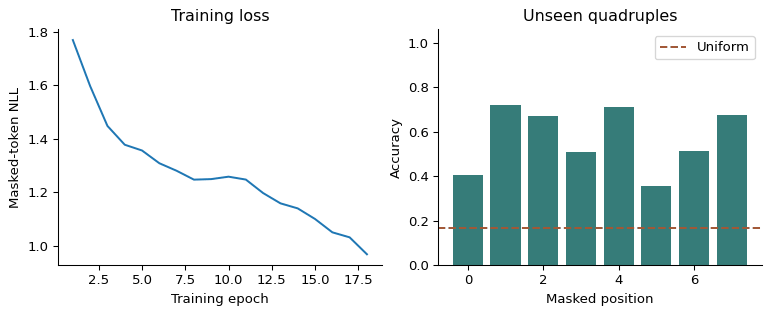

In [3]:
model.eval()
scores = []
with torch.no_grad():
    for p in range(8):
        pos = torch.full((len(test),), p)
        damaged, expected = mask_one(test, pos)
        logits = model(damaged)[:, p]
        scores.append(
            (
                p,
                len(test),
                float((logits.argmax(1) == expected).float().mean()),
                float(F.cross_entropy(logits, expected)),
            )
        )
report(["Masked site", "Examples", "Test accuracy", "Test NLL (nats)"], scores)
fig, axes = plt.subplots(1, 2, figsize=(8, 3.2), layout="constrained")
axes[0].plot(np.arange(1, len(curve) + 1), curve)
axes[0].set(xlabel="Training epoch", ylabel="Masked-token NLL", title="Training loss")
axes[1].bar(range(8), [r[2] for r in scores], color="#367c79")
axes[1].axhline(1 / 6, ls="--", color="#a25836", label="Uniform")
axes[1].set(
    xlabel="Masked position", ylabel="Accuracy", ylim=(0, 1.06), title="Unseen quadruples"
)
axes[1].legend()
plt.show()

## Interpreting the result

Accuracy ranged from 35.4% to 72.0% across the eight masked sites, compared with 16.7% for a uniform guess. The learned retrieval rule worked unevenly across positions on unseen quadruples.

A mask in the first half requires access to a later position. The split measures whether the model can retrieve from a sequence combination it did not see in training.

## Exercise

Add a causal mask. Predict which four positions should become difficult before inspecting the results.

## References

[Devlin et al. (2019), BERT](https://arxiv.org/abs/1810.04805)

[Vaswani et al. (2017), Attention Is All You Need](https://arxiv.org/abs/1706.03762)